C:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset Shape: (2000, 21)
Eligibility Distribution:
 eligible
1    1315
0     685
Name: count, dtype: int64
✅ Model training completed!

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.93      0.74      0.82       171
           1       0.88      0.97      0.92       329

    accuracy                           0.89       500
   macro avg       0.90      0.86      0.87       500
weighted avg       0.90      0.89      0.89       500

ROC-AUC: 0.9226
5-Fold CV ROC-AUC: 0.9279 ± 0.0096


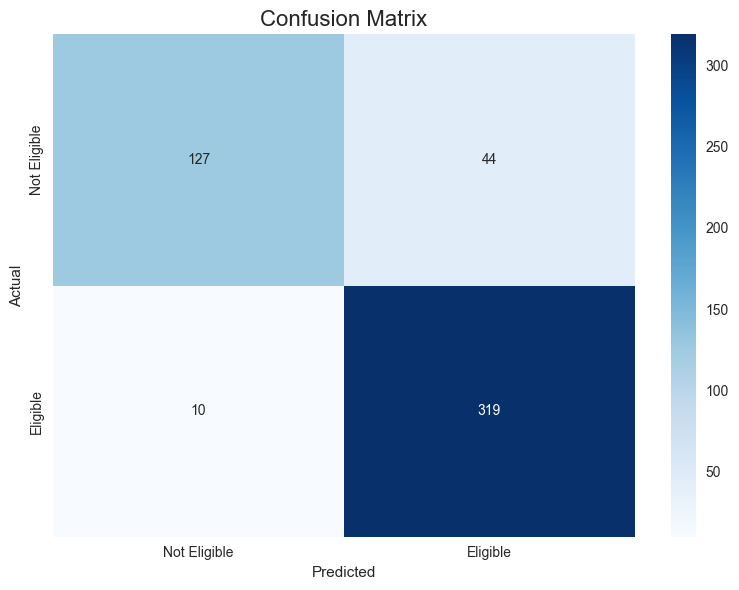

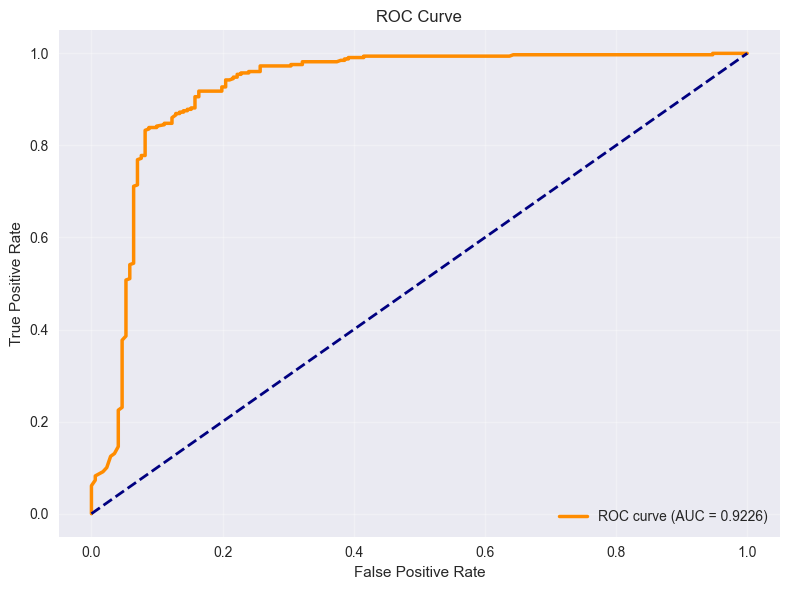

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Set plot style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# -----------------------------
# 1. Load & Prepare Data
# -----------------------------
df = pd.read_csv("elderly_incentive_dataset.csv")

# Relevant features only (excluding protected/derived columns)
feature_cols = [
    'age', 'income', 'employment_status', 'housing_status', 'health_status',
    'disability', 'chronic_illness', 'caregiver', 'family_support',
    'healthcare_access', 'national_id', 'location'
]

X = df[feature_cols]
y = df['eligible']

print(f"Dataset Shape: {df.shape}")
print("Eligibility Distribution:\n", y.value_counts())

# -----------------------------
# 2. Train-Test Split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# -----------------------------
# 3. Preprocessing Pipeline
# -----------------------------
categorical_cols = ['employment_status', 'housing_status', 'health_status',
                    'disability', 'chronic_illness', 'caregiver', 'family_support',
                    'healthcare_access', 'national_id', 'location']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'  # age & income
)

# -----------------------------
# 4. Random Forest Model
# -----------------------------
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    bootstrap=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', rf)
])

model.fit(X_train, y_train)
print("✅ Model training completed!")

# -----------------------------
# 5. Evaluation + Plots
# -----------------------------
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

# Cross-validation
cv_scores = cross_val_score(model, X, y, cv=5, scoring='roc_auc')
print(f"5-Fold CV ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# Confusion Matrix Plot
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Eligible', 'Eligible'],
            yticklabels=['Not Eligible', 'Eligible'])
plt.title('Confusion Matrix', fontsize=16)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, 
         label=f'ROC curve (AUC = {roc_auc_score(y_test, y_prob):.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

SHAP values shape: (500, 15, 2)


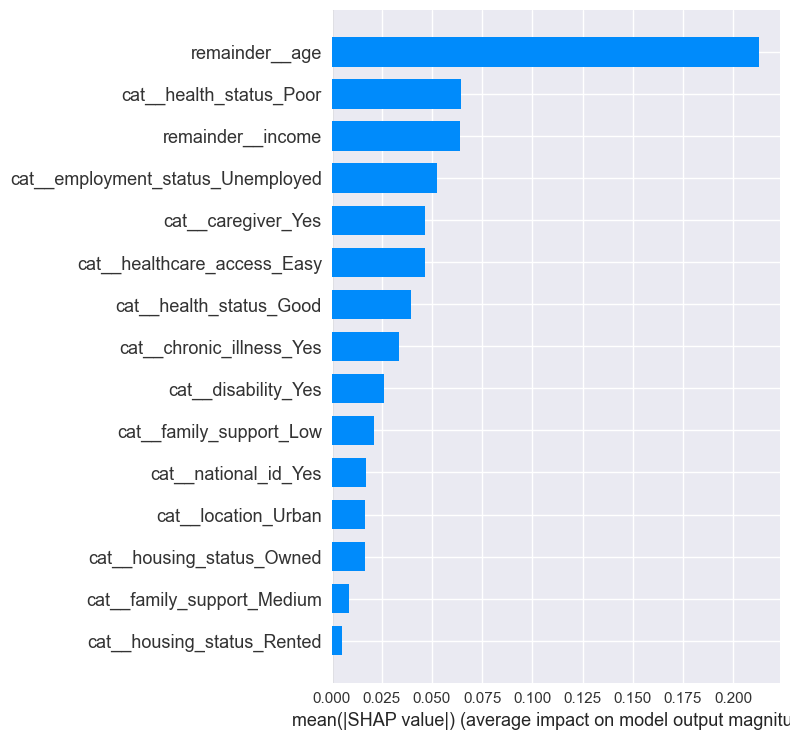

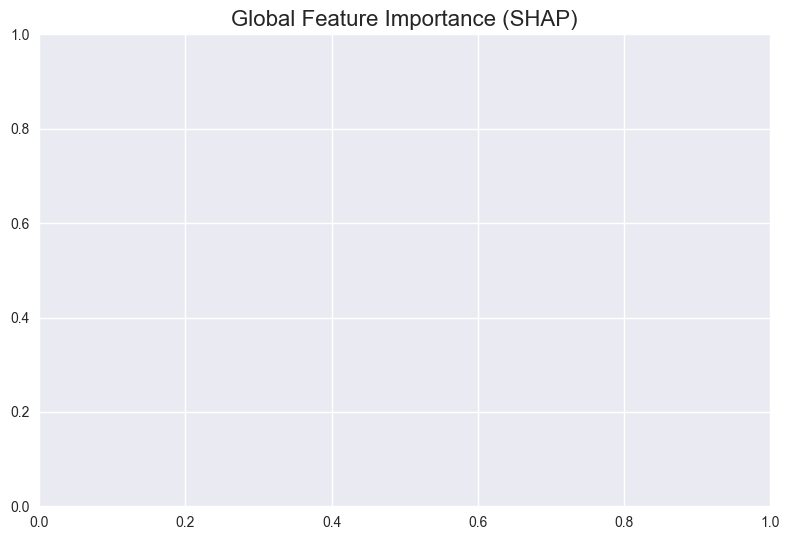

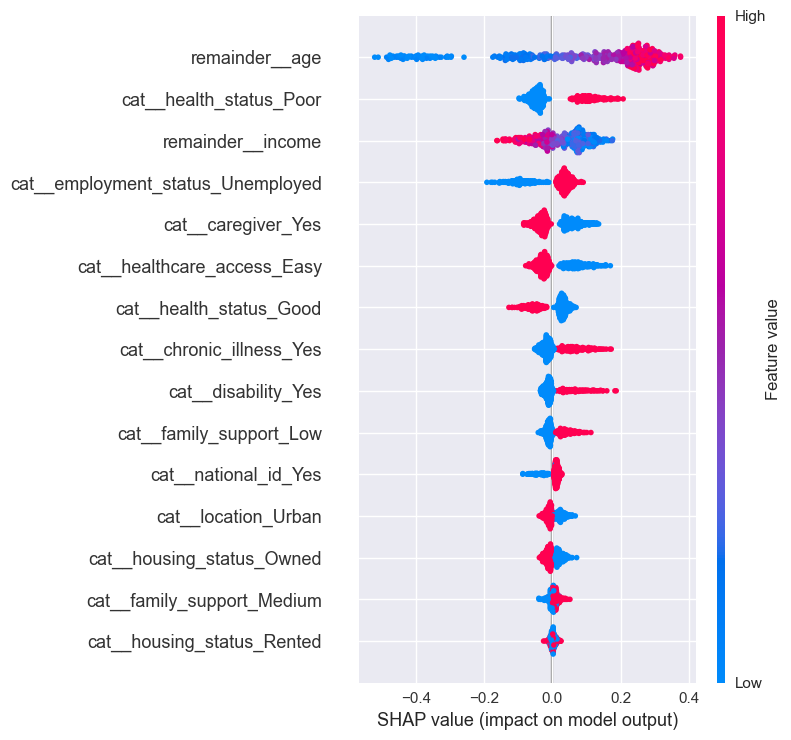

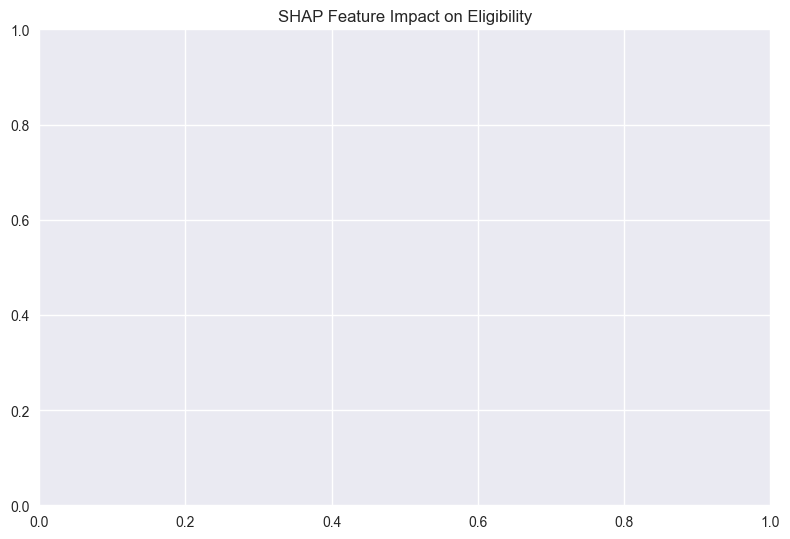

In [2]:
# -----------------------------
# 6. SHAP Explainability (Fixed for newer SHAP versions)
# -----------------------------
preprocessor_fitted = model.named_steps['preprocessor']
X_test_transformed = preprocessor_fitted.transform(X_test)
feature_names = preprocessor_fitted.get_feature_names_out()

explainer = shap.TreeExplainer(model.named_steps['classifier'])
shap_values = explainer.shap_values(X_test_transformed)

print(f"SHAP values shape: {np.asarray(shap_values).shape}")

# Global Feature Importance (Bar)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values[:,:,1], X_test_transformed, 
                  feature_names=feature_names, plot_type="bar")
plt.title("Global Feature Importance (SHAP)", fontsize=16)
plt.tight_layout()
plt.show()

# SHAP Summary (Beeswarm)
shap.summary_plot(shap_values[:,:,1], X_test_transformed, feature_names=feature_names)
plt.title("SHAP Feature Impact on Eligibility")
plt.tight_layout()
plt.show()

In [3]:
# -----------------------------
# 7. Save Model
# -----------------------------
joblib.dump(model, 'elderly_incentive_rf_model.pkl')
print("✅ Model saved as 'elderly_incentive_rf_model.pkl'")

✅ Model saved as 'elderly_incentive_rf_model.pkl'


In [4]:
# -----------------------------
# 8. Prediction Function
# -----------------------------
def predict_eligibility(applicant: dict):
    input_df = pd.DataFrame([applicant])
    prob = model.predict_proba(input_df)[0, 1]
    decision = "✅ Eligible" if prob >= 0.5 else "❌ Not Eligible"
    confidence = "High" if abs(prob - 0.5) > 0.3 else "Medium"
    
    return {
        "probability": round(float(prob), 4),
        "decision": decision,
        "confidence": confidence
    }

# Test sample
sample = {
    "age": 75,
    "income": 35000,
    "employment_status": "Unemployed",
    "housing_status": "Rented",
    "health_status": "Poor",
    "disability": "Yes",
    "chronic_illness": "Yes",
    "caregiver": "No",
    "family_support": "Low",
    "healthcare_access": "Difficult",
    "national_id": "Yes",
    "location": "Rural"
}

print("\nTest Prediction:", predict_eligibility(sample))


Test Prediction: {'probability': 0.91, 'decision': '✅ Eligible', 'confidence': 'High'}
